# 04 · The graph

**Goal:** an interactive page (`docs/index.html`) that shows the project's main point: an article's **theme** (its cluster, Step 3) and its **closeness** to the war (its similarity to the seed, Step 2) are separate things.

The page has two views and animates between them:

| View | Position means |
|---|---|
| **Radial** | angle = theme (one wedge per cluster); distance from the center = rank in similarity to the seed |
| **Network** | similar articles are pulled together (the Step 3 force layout) |

This notebook computes both layouts in Python and exports them with the article details to `docs/data.js`. The browser only animates between saved positions, so the picture is the same every time and loads fast. The layout functions are in `src/layout.py`.

In [1]:
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.colors import LinearSegmentedColormap

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
import clustering
import layout
import similarity

SEED = "Hundred Years' War"
K = 10  # neighbors per article, as in Step 3

data = ROOT / "data" / "processed"
clusters = pd.read_parquet(data / "clusters.parquet").set_index("title")
seed_similarity = pd.read_parquet(data / "seed_similarity.parquet").set_index("title")
articles = pd.read_parquet(data / "articles.parquet").set_index("title")
pairs = pd.read_parquet(data / "pairs.parquet")
pairs = pairs[(pairs["a"] != SEED) & (pairs["b"] != SEED)]
mw = similarity.from_pairs(pairs, "milne_witten")
inlink = similarity.from_pairs(pairs, "inlink")
outlink = similarity.from_pairs(pairs, "outlink")
links = pd.read_parquet(data / "links.parquet")
seed_links = links[links["source"] == SEED].drop_duplicates("target").set_index("target")

titles = mw.index
labels = clusters.loc[titles, "cluster"]
names = clusters.groupby("cluster")["cluster_name"].first()
seed_rank = seed_similarity.loc[titles, "milne_witten_rank"]
graph = clustering.knn_graph(mw, K)
print(f"{len(titles)} articles in {labels.nunique()} clusters | {graph.number_of_edges():,} edges")

# Closeness colors: one blue ramp, dark = most similar to the seed.
BLUES = ["#cde2fb", "#9ec5f4", "#6da7ec", "#3987e5", "#256abf", "#184f95", "#0d366b"]
closeness_cmap = LinearSegmentedColormap.from_list("closeness", BLUES[::-1])

788 articles in 12 clusters | 6,243 edges


## 1. Network layout

The same force layout as Step 3: every edge of the neighbor graph is a spring as strong as the pair's similarity, and all articles repel each other. Color shows closeness to the seed (dark = closer). The two don't line up: close and distant articles are mixed across most regions.

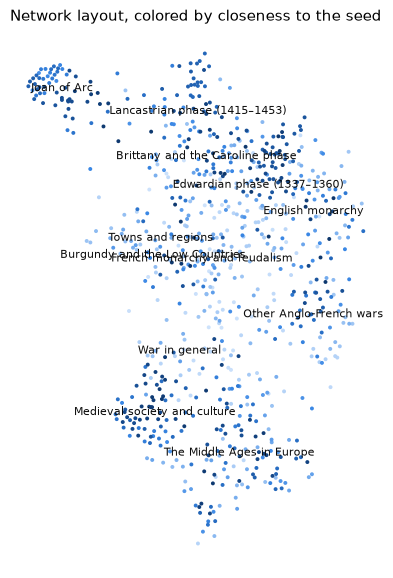

In [2]:
network = layout.network_layout(graph, seed=0).loc[titles]

def preview(xy, ax, title):
    order = np.argsort(-seed_rank.to_numpy())  # draw the closest articles last, on top
    ax.scatter(xy["x"].to_numpy()[order], xy["y"].to_numpy()[order], s=8, linewidths=0,
               c=seed_rank.to_numpy()[order], cmap=closeness_cmap)
    ax.set_title(title, fontsize=11)
    ax.set_aspect("equal")
    ax.set_axis_off()

fig, ax = plt.subplots(figsize=(7, 7))
preview(network, ax, "Network layout, colored by closeness to the seed")
for c, name in names.items():
    x, y = network[labels == c].median()
    ax.annotate(name, (x, y), ha="center", fontsize=8, color="#0b0b0b")

## 2. Radial layout

The seed sits at the center, and each cluster gets a wedge sized by its number of articles.

- **Order of the wedges:** similar themes sit side by side. Two clusters' similarity is the mean Milne–Witten similarity between their articles. The order comes from hierarchical clustering of the clusters, with the leaves reordered so that neighbors are as similar as possible (**optimal leaf ordering**).
- **Distance from the center:** √(rank / 788), with rank 1 the article most similar to the seed. With the square root, each ring of equal area holds the same number of articles, so the center isn't crowded and the edge isn't sparse.
- **Within a wedge:** articles take angles in steps of the golden ratio, so articles with neighboring ranks land far apart instead of on top of each other.

In [3]:
order = layout.cluster_order(mw, labels)
radial, wedges = layout.radial_layout(labels, seed_rank, order)

own = labels.to_numpy()
between = pd.DataFrame(
    [[mw.to_numpy()[np.ix_(own == a, own == b)].mean() for b in order] for a in order],
    index=names[order], columns=names[order],
)
between.round(2)

cluster_name,War in general,Medieval society and culture,The Middle Ages in Europe,Edwardian phase (1337–1360),English monarchy,Burgundy and the Low Countries,French monarchy and feudalism,Brittany and the Caroline phase,Lancastrian phase (1415–1453),Joan of Arc,Other Anglo-French wars,Towns and regions
cluster_name,,,,,,,,,,,,
War in general,0.68,0.40,0.41,0.33,0.30,0.33,0.29,0.35,0.38,0.27,0.43,0.25
Medieval society and culture,0.40,0.89,0.73,0.42,0.48,0.50,0.49,0.48,0.45,0.37,0.43,0.36
The Middle Ages in Europe,0.41,0.73,0.78,0.33,0.39,0.43,0.43,0.36,0.33,0.27,0.47,0.36
Edwardian phase (1337–1360),0.33,0.42,0.33,0.56,0.50,0.46,0.48,0.61,0.61,0.45,0.45,0.42
English monarchy,0.30,0.48,0.39,0.50,0.70,0.49,0.55,0.59,0.60,0.39,0.48,0.41
Burgundy and the Low Countries,0.33,0.50,0.43,0.46,0.49,0.81,0.61,0.59,0.63,0.46,0.50,0.45
French monarchy and feudalism,0.29,0.49,0.43,0.48,0.55,0.61,0.75,0.61,0.61,0.48,0.50,0.49
Brittany and the Caroline phase,0.35,0.48,0.36,0.61,0.59,0.59,0.61,0.81,0.76,0.55,0.56,0.49
Lancastrian phase (1415–1453),0.38,0.45,0.33,0.61,0.60,0.63,0.61,0.76,0.93,0.84,0.57,0.52


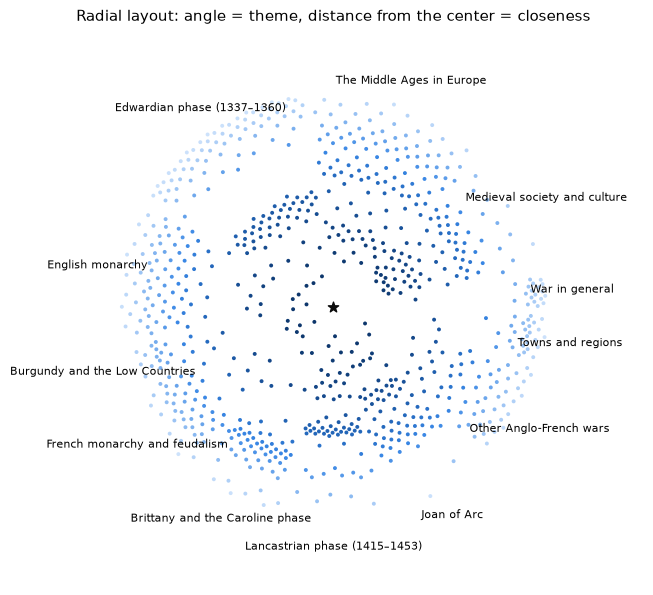

In [4]:
fig, ax = plt.subplots(figsize=(8, 8))
preview(radial, ax, "Radial layout: angle = theme, distance from the center = closeness")
ax.scatter([0], [0], s=60, marker="*", color="#0b0b0b")
for c, (start, end) in wedges.items():
    mid = (start + end) / 2
    ax.annotate(names[c], (1.12 * np.cos(mid), 1.12 * np.sin(mid)), ha="center", va="center", fontsize=8)
ax.set(xlim=(-1.45, 1.45), ylim=(-1.3, 1.3));

Wedges whose articles sit near the center are themes close to the war, such as the Lancastrian phase and Joan of Arc. Wedges whose articles sit near the edge are themes farther away, such as war in general and towns and regions. This matches the cluster profiles in Step 3.

## 3. Export

Each article also carries the metadata the page filters on (length, whether it links back to the seed, whether the seed's link came from a template) and its 10 most similar articles with the pair's three scores, for the table. `docs/data.js` holds everything the page needs, as one JavaScript object (`window.GRAPH`). A plain JSON file would need a web server: browsers block reading local files with `fetch`, but a script tag works when you just double-click `index.html`.

In [5]:
def cut(text, limit=400):
    # Shorten to whole words, ending with an ellipsis.
    text = (text or "").strip()
    return text if len(text) <= limit else text[:limit].rsplit(" ", 1)[0] + "…"

position_of = {t: i for i, t in enumerate(titles)}
nearest = clustering.neighbors(mw, K)
round3 = lambda v: round(float(v), 3)

nodes = []
for i, t in enumerate(titles):
    s = seed_similarity.loc[t]
    nodes.append({
        "title": t,
        "cluster": int(labels[t]),
        "shortdesc": articles.at[t, "shortdesc"] or "",
        "paragraph": cut(articles.at[t, "first_paragraph"]),
        "rank": int(s["milne_witten_rank"]),
        "milne_witten": round3(s["milne_witten"]),
        "outlink": round3(s["outlink"]),
        "inlink": round3(s["inlink"]),
        "centrality": round3(clusters.at[t, "centrality"]),
        "outside_share": round3(clusters.at[t, "outside_share"]),
        "radial": [round3(radial.at[t, "x"]), round3(radial.at[t, "y"])],
        "network": [round3(network.at[t, "x"]), round3(network.at[t, "y"])],
        "word_count": int(articles.at[t, "word_count"]),
        "links_to_seed": bool(articles.at[t, "links_to_seed"]),
        "from_template": bool(seed_links.at[t, "from_template"]),
        # The 10 most similar articles: [index, Milne–Witten, in-link, out-link] for the pair.
        "neighbors": [[int(j), round3(mw.iat[i, j]), round3(inlink.iat[i, j]), round3(outlink.iat[i, j])]
                      for j in nearest[i]],
    })

edges = [[position_of[u], position_of[v], round3(w)] for u, v, w in graph.edges(data="weight")]

cluster_info = []
for c in order:
    start, end = wedges[c]
    members = network[labels == c]
    cluster_info.append({
        "id": int(c),
        "name": names[c],
        "size": int((labels == c).sum()),
        "wedge": [round3(start), round3(end)],
        "network_label": [round3(members["x"].median()), round3(members["y"].median())],
    })

seed = {
    "title": SEED,
    "shortdesc": articles.at[SEED, "shortdesc"] or "",
    "paragraph": cut(articles.at[SEED, "first_paragraph"]),
}

assert len(nodes) == 788 and SEED not in position_of, "788 articles, seed separate"
assert all(np.isfinite(n["radial"] + n["network"]).all() for n in nodes), "finite positions"
assert all(0 <= i < len(nodes) and 0 <= j < len(nodes) for i, j, _ in edges), "valid edges"
assert sum(c["size"] for c in cluster_info) == len(nodes), "every article in one cluster"

out = ROOT / "docs" / "data.js"
out.parent.mkdir(exist_ok=True)
payload = {"seed": seed, "nodes": nodes, "edges": edges, "clusters": cluster_info}
out.write_text("window.GRAPH = " + json.dumps(payload, ensure_ascii=False, separators=(",", ":")) + ";\n", encoding="utf-8")
print(f"wrote {out.relative_to(ROOT)}: {len(nodes)} articles, {len(edges):,} edges, "
      f"{len(cluster_info)} clusters, {out.stat().st_size / 1e6:.2f} MB")

wrote docs/data.js: 788 articles, 6,243 edges, 12 clusters, 0.81 MB


## 4. The page

Open `docs/index.html` in a browser (double-click it), or serve the folder with `python -m http.server -d docs` and go to http://localhost:8000.

- **Radial / Network** toggle at the top animates between the two layouts.
- **Hover** an article for its title, theme and rank; **click** it for details.
- **Search** for an article by name, or for the seed.
- **Filters** (multiple choice): theme, closeness to the war, how the seed links to it, whether it links back, length, and bridge articles. Within a filter any checked option matches; across filters all must match. Articles that don't match fade out.
- **Table** at the bottom: the 10 articles most related to the selected article, or to the seed when nothing is selected.
- **Reset** clears the zoom, the filters and the selection.